# Transfer learning with a pretrained ResNet-18
A ResNet-18 trained on ImageNet, adapted to our 5 styles.

1. **Step A**: freeze the backbone, train only the new head.
2. **Step B**: unfreeze the last block `layer4` and fine-tune it with the head.
3. **Errors**: confusion matrix and wrong paintings.
4. **Comparison** with the MLP: accuracy, size, CPU time (the director's question).
5. **Idea from NVIDIA VSS**: a confidence guardrail and "similar artworks" search with the ResNet features.

**On Colab only** (GPU: *Runtime → Change runtime type → T4 GPU*): uncomment and run the cell below first. It mounts Google Drive, clones the repo and copies the images into `data/`. Change `DATA_ON_DRIVE` to where the `wikiart_style5` folder is on your Drive. Locally (VS Code / Jupyter with `.venv`), skip it.

In [2]:
#  --- Colab only ---
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_ON_DRIVE = "/content/drive/MyDrive/wikiart_style5"     # <- adapt
# !git clone -q https://github.com/raniamehria/museum-guide.git /content/museum-guide   # main: data.py + split.csv
# %cd /content/museum-guide
# !rm -rf data/wikiart_style5 && mkdir -p data && cp -r "{DATA_ON_DRIVE}" data/wikiart_style5   # fresh copy: running it twice must not nest the folder
# !find data/wikiart_style5 -name "*.jpg" | wc -l                                             # must print 1500
# !ls data/wikiart_style5 | head

Mounted at /content/drive
/content/museum-guide
1500
Baroque
Cubism
Impressionism
metadata.csv
Pop_Art
subset_info.json
Ukiyo_e


## Setup
Imports, fixed random seeds (same result every run) and the settings: 5 epochs per step, 5 styles.

In [3]:
import os
import sys
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")                  # run from the repo root, where data/ and splits/ are
sys.path.insert(0, "src")           # find the museum_guide package (src/museum_guide), no install needed

import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights

from museum_guide.data import get_dataloaders, load_images

np.random.seed(0)
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS_HEAD = 5
EPOCHS_FT = 5
N_CLASSES = 5
CLASSES = ["Baroque", "Cubism", "Impressionism", "Pop_Art", "Ukiyo_e"]
print("device:", device)

device: cpu


## Data
The shared split (1 000 train / 250 validation / 250 test, grouped by artist). Images are normalised with the ImageNet mean and std, because the pretrained network expects inputs prepared like the photos it was trained on.

In [4]:
train_loader, val_loader, test_loader = get_dataloaders("resnet", batch_size=64)
train_eval_loader = DataLoader(train_loader.dataset, batch_size=250)     # train set measured without shuffling
loss_fn = nn.CrossEntropyLoss()
xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape))

split          test  train  val
label                          
Baroque          52    197   51
Cubism           53    204   43
Impressionism    57    188   55
Pop_Art          52    191   57
Ukiyo_e          36    220   44
Split validated!
one batch: (64, 3, 128, 128) (64,)


## Helper functions
Evaluation, the training loop (keeps the best validation epoch), learning curves, macro-F1 and the CPU time for one image.

In [5]:
# Loss and accuracy of a model on one data loader
def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


# One training epoch; model.eval() keeps the BatchNorm statistics learned on ImageNet
def train_transfer_epoch(model, loader, loss_fn, optimizer):
    model.eval()                                   # batch norm keeps its ImageNet statistics
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()


# Training loop that records loss and accuracy at every epoch
def new_history():
    return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}


def record(history, model, optimizer):
    """Measure the model on the training and validation sets and append the results to the history."""
    tl, ta = evaluate(model, train_eval_loader, loss_fn)
    vl, va = evaluate(model, val_loader, loss_fn)
    history["train_loss"].append(tl); history["train_acc"].append(ta)
    history["val_loss"].append(vl); history["val_acc"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])


def fit(model, optimizer, n_epochs, train_epoch_fn=train_transfer_epoch, scheduler=None, verbose=False):
    torch.manual_seed(1)                       # same order of the mini-batches for every run
    history = new_history()
    best_acc, best_state, best_epoch = -1.0, None, 0
    for epoch in range(n_epochs):
        train_epoch_fn(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        if scheduler is not None:
            scheduler.step()
        if history["val_acc"][-1] > best_acc:  # early stopping: remember the best validation epoch
            best_acc, best_epoch = history["val_acc"][-1], epoch + 1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"epoch {epoch + 1:2d}  train loss {history['train_loss'][-1]:.3f}  "
                  f"val loss {history['val_loss'][-1]:.3f}  val acc {history['val_acc'][-1]:.3f}")
    model.load_state_dict(best_state)          # keep the best epoch, not the last one
    print(f"kept epoch {best_epoch} (best val acc {best_acc:.3f})")
    return history


def plot_history(history, title=""):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


# Extra measures for the director's question: macro-F1 and CPU time per image
def macro_f1(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(device)).argmax(dim=1).cpu())
            labels.append(yb)
    return f1_score(torch.cat(labels), torch.cat(preds), average="macro")


def cpu_latency_ms(model, n=50, shape=(1, 3, 128, 128), threads=1):
    """Milliseconds to classify ONE image on the CPU. threads=1: one core, like a modest kiosk CPU."""
    model = model.cpu().eval()
    x = torch.randn(*shape)                        # one visitor = one image (batch 1)
    old_threads = torch.get_num_threads()
    torch.set_num_threads(threads)
    with torch.no_grad():
        for _ in range(5):                         # warm-up, not timed
            model(x)
        t0 = time.perf_counter()
        for _ in range(n):
            model(x)
    torch.set_num_threads(old_threads)             # give the other cells all the cores back
    return (time.perf_counter() - t0) / n * 1000


def file_size_mb(model, path):
    """Size of the saved weights: what the kiosk has to store."""
    torch.save(model.state_dict(), path)
    return os.path.getsize(path) / 1e6

## Step A: a new head on a frozen backbone
Load ResNet-18 pretrained on ImageNet and replace its last layer (1000 ImageNet classes) by a new layer for our 5 styles.

In [6]:
torch.manual_seed(0)
model_tl = resnet18(weights=ResNet18_Weights.DEFAULT)
print("original head:", model_tl.fc)
model_tl.fc = nn.Linear(512, N_CLASSES)
model_tl = model_tl.to(device)
print("new head:", model_tl.fc, "| parameters:", count_parameters(model_tl))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]

original head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=5, bias=True) | parameters: 11179077


Freeze every layer except the new head: only 512 × 5 + 5 = 2 565 parameters are trained.

In [7]:
for p in model_tl.parameters():
    p.requires_grad = False
for p in model_tl.fc.parameters():
    p.requires_grad = True
n_trainable = count_parameters(model_tl, trainable_only=True)
print("Trainable:", n_trainable, "of", count_parameters(model_tl))          # 512 x 5 + 5 = 2565

Trainable: 2565 of 11179077


Train the head only (Adam, learning rate 3e-3), then measure test accuracy and macro-F1.

epoch  1  train loss 0.785  val loss 0.896  val acc 0.628
epoch  2  train loss 0.586  val loss 0.781  val acc 0.708
epoch  3  train loss 0.487  val loss 0.700  val acc 0.724
epoch  4  train loss 0.467  val loss 0.780  val acc 0.708
epoch  5  train loss 0.393  val loss 0.733  val acc 0.740
kept epoch 5 (best val acc 0.740)


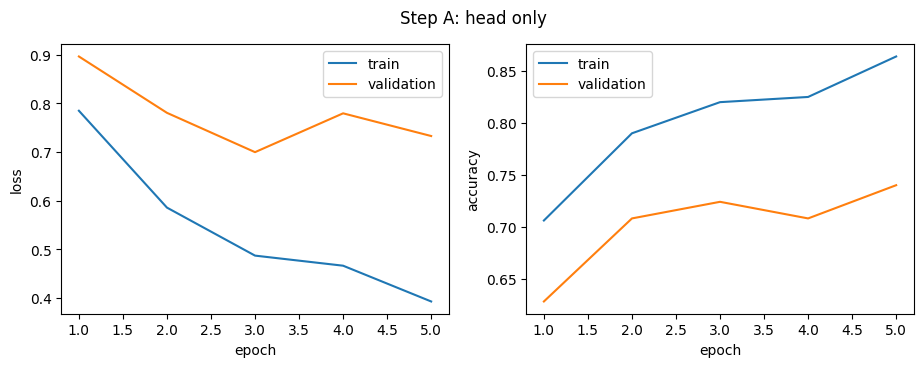

Head only: test accuracy 0.732, macro-F1 0.734 (389 s). Chance level is 0.20.


In [8]:
t0 = time.time()
optimizer = torch.optim.Adam(model_tl.fc.parameters(), lr=3e-3)
history_head = fit(model_tl, optimizer, EPOCHS_HEAD, verbose=True)
acc_head = evaluate(model_tl, test_loader, loss_fn)[1]
f1_head = macro_f1(model_tl, test_loader)
time_head = time.time() - t0
plot_history(history_head, "Step A: head only")
print(f"Head only: test accuracy {acc_head:.3f}, macro-F1 {f1_head:.3f} ({time_head:.0f} s). Chance level is 0.20.")

## Step B: fine-tune the last block
Unfreeze `layer4`, the most ImageNet-specific block, and train it with a 10x smaller learning rate than the head, to adjust the pretrained weights without destroying them.

Trainable: 8396293 of 11179077
epoch  1  train loss 0.254  val loss 0.692  val acc 0.768
epoch  2  train loss 0.047  val loss 0.781  val acc 0.752
epoch  3  train loss 0.029  val loss 0.899  val acc 0.748
epoch  4  train loss 0.012  val loss 0.748  val acc 0.788
epoch  5  train loss 0.014  val loss 0.867  val acc 0.744
kept epoch 4 (best val acc 0.788)


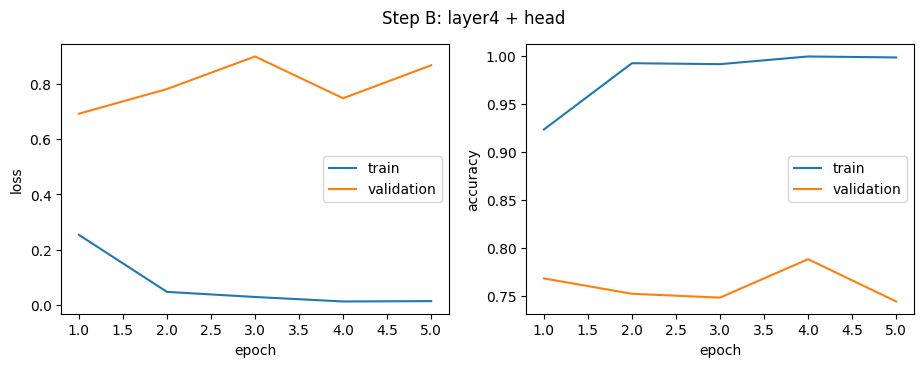

Fine-tuned: test accuracy 0.776, macro-F1 0.776 (head only 0.732) in 418 s.


In [9]:
t0 = time.time()
for p in model_tl.layer4.parameters():
    p.requires_grad = True
print("Trainable:", count_parameters(model_tl, trainable_only=True), "of", count_parameters(model_tl))
optimizer = torch.optim.Adam([{"params": model_tl.layer4.parameters(), "lr": 1e-4},
                              {"params": model_tl.fc.parameters(), "lr": 1e-3}])
history_ft = fit(model_tl, optimizer, EPOCHS_FT, verbose=True)
acc_ft = evaluate(model_tl, test_loader, loss_fn)[1]
f1_ft = macro_f1(model_tl, test_loader)
time_ft = time.time() - t0
plot_history(history_ft, "Step B: layer4 + head")
print(f"Fine-tuned: test accuracy {acc_ft:.3f}, macro-F1 {f1_ft:.3f} (head only {acc_head:.3f}) in {time_ft:.0f} s.")

Save the weights (outside Git) and measure the cost on a kiosk: CPU time per image and file size.

In [10]:
os.makedirs("models", exist_ok=True)                            # weights stay outside Git (.gitignore)
size_mb = file_size_mb(model_tl, "models/resnet18.pt")
lat_resnet = cpu_latency_ms(model_tl)                                       # 1 core: a modest kiosk CPU
lat_resnet_all = cpu_latency_ms(model_tl, threads=torch.get_num_threads())  # all the cores of this computer
print(f"CPU time per image: {lat_resnet:.1f} ms on 1 core, {lat_resnet_all:.1f} ms on {torch.get_num_threads()} cores")
print(f"size: {size_mb:.1f} MB | parameters: {count_parameters(model_tl):,}")
model_tl = model_tl.to(device)

CPU time per image: 25.4 ms on 1 core, 26.1 ms on 1 cores
size: 44.8 MB | parameters: 11,179,077


### Steps A and B together
The dashed line is where `layer4` is unfrozen. If the train loss keeps falling while the validation loss rises, the model is **overfitting** (8.4 million trainable parameters for 1 000 paintings); `fit` keeps the best validation epoch (early stopping).

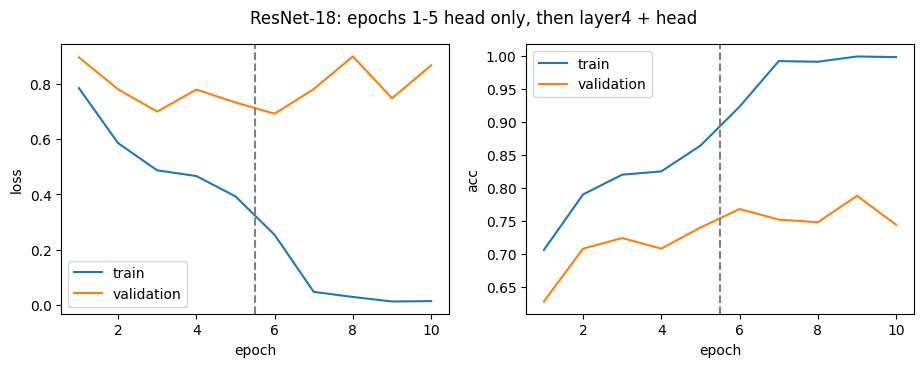

In [11]:
history = {k: history_head[k] + history_ft[k] for k in history_head}
e = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key in zip(axes, ["loss", "acc"]):
    ax.plot(e, history[f"train_{key}"], label="train")
    ax.plot(e, history[f"val_{key}"], label="validation")
    ax.axvline(EPOCHS_HEAD + 0.5, color="grey", linestyle="--")
    ax.set_xlabel("epoch"); ax.set_ylabel(key); ax.legend()
fig.suptitle(f"ResNet-18: epochs 1-{EPOCHS_HEAD} head only, then layer4 + head")
plt.show()

## Errors of the fine-tuned model
Same analysis as `mlp.ipynb`: confusion matrix and the paintings it gets wrong.

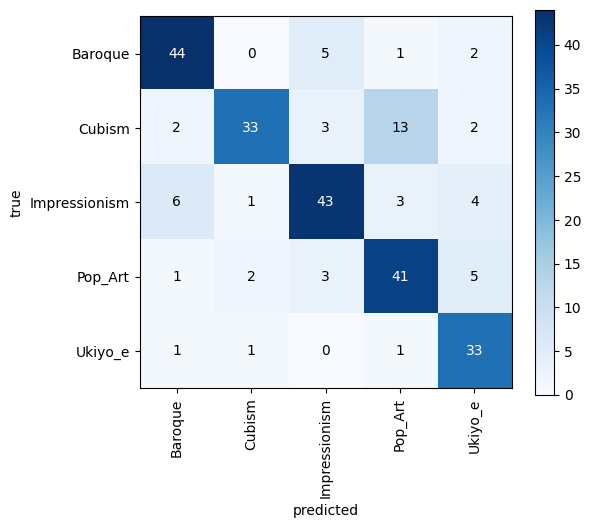

Baroque        accuracy 0.85
Cubism         accuracy 0.62
Impressionism  accuracy 0.75
Pop_Art        accuracy 0.79
Ukiyo_e        accuracy 0.92
most frequent mistake: Cubism predicted as Pop_Art (13 times)


In [12]:
model_tl.eval()
preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(model_tl(xb.to(device)).argmax(dim=1).cpu())
        labels.append(yb)
preds, labels = torch.cat(preds), torch.cat(labels)

cm = confusion_matrix(labels, preds, labels=range(N_CLASSES))
off = cm.copy()
np.fill_diagonal(off, 0)
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(N_CLASSES), CLASSES, rotation=90); plt.yticks(range(N_CLASSES), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
for i, c in enumerate(CLASSES):
    print(f"{c:14s} accuracy {cm[i, i] / cm[i].sum():.2f}")
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")

The paintings the model gets wrong (title: true style / predicted style).

56 mistakes out of 250 (title: true / predicted)


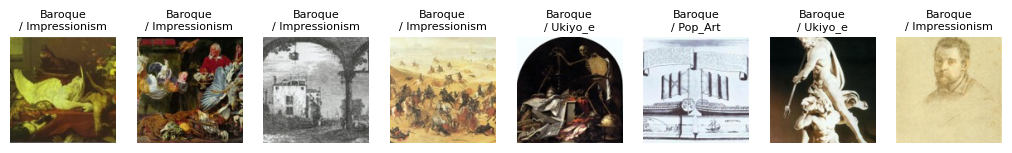

In [13]:
X, y, meta = load_images()                                         # images in [0, 1], to look at them
split = pd.read_csv("splits/split.csv")
X_test_raw = X[torch.tensor((split["split"] == "test").values)]
X_train_raw = X[torch.tensor((split["split"] == "train").values)]


def show_images(images, titles, n=8):
    n = min(n, len(images))
    if n == 0:
        return
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.0), squeeze=False)
    for ax, img, title in zip(axes[0], images[:n], titles[:n]):
        ax.imshow(img.permute(1, 2, 0))                             # (3, H, W) -> (H, W, 3)
        ax.set_title(title, fontsize=8); ax.axis("off")
    plt.show()


wrong = (preds != labels).nonzero(as_tuple=True)[0]
print(len(wrong), "mistakes out of", len(labels), "(title: true / predicted)")
show_images(X_test_raw[wrong], [f"{CLASSES[labels[i]]}\n/ {CLASSES[preds[i]]}" for i in wrong])

## Comparison with the MLP (the director's question)
Same split, same 250 test images. The MLP number comes from `mlp.ipynb` (Tâche 1); the classical baseline is compared in Tâche 4. With 250 test images, about ±3 points is noise.
The CPU time is measured here for every model with the same function (1 image, like one visitor at a kiosk); it does not depend on the trained weights, only on the architecture.

model,test accuracy,trained parameters,CPU ms / image (1 core),size MB
chance (1 / 5),0.200,0,0.00,0.00
"MLP, 3 ReLU layers",0.356,"3,187,461",0.57,12.75
"ResNet-18, head only (A)",0.732,"2,565",25.42,44.79
"ResNet-18, layer4 + head (B)",0.776,"8,396,293",25.42,44.79


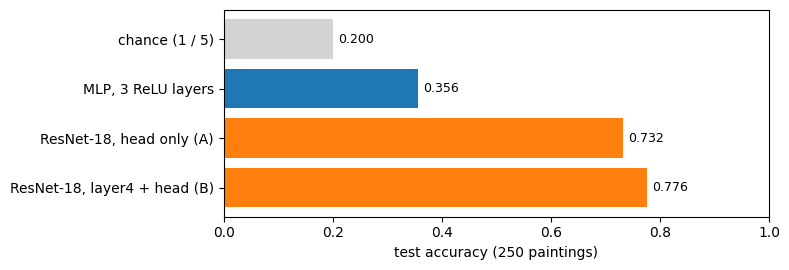

In [19]:
MLP_ACC = 0.356       # test accuracy of the tuned MLP (mlp.ipynb)

mlp = nn.Sequential(nn.Flatten(), nn.Linear(3 * 64 * 64, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(),
                    nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 5))                  # same architecture as mlp.ipynb, only to measure time and size
lat_mlp = cpu_latency_ms(mlp, shape=(1, 3, 64, 64))
size_mlp = file_size_mb(mlp, "models/mlp_untrained.pt")             # the size depends on the architecture only

results = pd.DataFrame([
    ["chance (1 / 5)", 0.20, 0, 0.0, 0.0],
    ["MLP, 3 ReLU layers", MLP_ACC, count_parameters(mlp), lat_mlp, size_mlp],
    ["ResNet-18, head only (A)", acc_head, n_trainable, lat_resnet, size_mb],
    ["ResNet-18, layer4 + head (B)", acc_ft, count_parameters(model_tl, trainable_only=True), lat_resnet, size_mb],
], columns=["model", "test accuracy", "trained parameters", "CPU ms / image (1 core)", "size MB"])
display(results.style.format({"test accuracy": "{:.3f}", "trained parameters": "{:,}",
                              "CPU ms / image (1 core)": "{:.2f}", "size MB": "{:.2f}"})
        .hide(axis="index"))

plt.figure(figsize=(8, 2.8))
plt.barh(results["model"], results["test accuracy"], color=["lightgrey", "tab:blue", "tab:orange", "tab:orange"])
for i, acc in enumerate(results["test accuracy"]):
    plt.text(acc + 0.01, i, f"{acc:.3f}", va="center", fontsize=9)
plt.xlim(0, 1); plt.xlabel("test accuracy (250 paintings)"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

## Idea from NVIDIA VSS: from a classifier to a museum guide
NVIDIA **VSS** (Video Search & Summarization) works in two phases: **offline**, a vision model turns every video chunk into captions and embeddings stored in a vector database; **online**, a question is embedded, the nearest chunks are found by similarity, and **guardrails** stop wrong answers.

We borrow the idea with simple tools, one artwork = one "chunk":

| VSS | Our guide |
|---|---|
| vision model (perception) | ResNet-18 fine-tuned on our 5 styles |
| embeddings + vector DB | 512-d ResNet feature of every painting, kept in one tensor |
| similarity search | cosine similarity, top 5 |
| guardrails | if the max softmax probability < τ, say "not sure" and show the top 3 |

The heavy part (computing the features) is done **once offline**; online, the kiosk only computes one feature and one matrix product, which fits a cheap CPU.

### 1. Guardrail: answer only when the model is confident
τ is chosen on the **validation** set (never on the test set): for each τ, how many paintings the guide answers, and how often it is right when it answers.

In [20]:
def probabilities(model, loader):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(torch.softmax(model(xb.to(device)), dim=1).cpu())
            labels.append(yb)
    return torch.cat(probs), torch.cat(labels)


val_probs, val_labels = probabilities(model_tl, val_loader)
conf, val_preds = val_probs.max(dim=1)
print("  tau  | answered | accuracy when answered")
for tau in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= tau
    acc = (val_preds[keep] == val_labels[keep]).float().mean().item() if keep.any() else float("nan")
    print(f"  {tau:.1f}  |  {keep.float().mean().item():5.0%}   |  {acc:.3f}")

  tau  | answered | accuracy when answered
  0.0  |   100%   |  0.788
  0.5  |    98%   |  0.795
  0.6  |    93%   |  0.810
  0.7  |    85%   |  0.836
  0.8  |    76%   |  0.869
  0.9  |    67%   |  0.892


What the kiosk says for one painting: the style and the story of the movement if the confidence is at least τ, otherwise "not sure" and the top 3.

In [21]:
TAU = 0.7                                      # choose it from the table above

STORIES = {                                    # what the guide tells the visitor about each movement
    "Baroque": "European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion "
               "(Caravaggio, Rubens, Rembrandt, Velazquez).",
    "Cubism": "Started in Paris around 1907-1908 with Picasso and Braque. Objects are broken into geometric facets "
              "and shown from several viewpoints at once.",
    "Impressionism": "France, from the 1860s-1870s (Monet, Renoir, Degas). Visible brushstrokes, outdoor scenes and changing light; "
                     "the name comes from Monet's 'Impression, Sunrise'.",
    "Pop_Art": "Britain and the United States, from the late 1950s (Warhol, Lichtenstein). Images taken from advertising, "
               "comics and everyday consumer products.",
    "Ukiyo_e": "Japanese woodblock prints and paintings of the Edo period, 17th to 19th century (Hokusai, Hiroshige): "
               "'pictures of the floating world'. They inspired many Impressionists.",
}


def guide_answer(probs):
    """What the kiosk says for one painting, from its 5 softmax probabilities."""
    p, k = probs.max(dim=0)
    if p >= TAU:
        return f"{CLASSES[k]} ({p:.0%}). {STORIES[CLASSES[k]]}"
    top3 = probs.topk(3)
    return "not sure: " + ", ".join(f"{CLASSES[i]} {q:.0%}" for q, i in zip(top3.values, top3.indices))


test_probs, test_labels = probabilities(model_tl, test_loader)
for i in range(5):
    print(f"true {CLASSES[test_labels[i]]:14s} -> guide: {guide_answer(test_probs[i])}")

true Baroque        -> guide: not sure: Impressionism 50%, Baroque 50%, Cubism 0%
true Baroque        -> guide: Baroque (99%). European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion (Caravaggio, Rubens, Rembrandt, Velazquez).
true Baroque        -> guide: not sure: Baroque 65%, Impressionism 35%, Ukiyo_e 0%
true Baroque        -> guide: Baroque (96%). European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion (Caravaggio, Rubens, Rembrandt, Velazquez).
true Baroque        -> guide: Baroque (95%). European art of the 17th and early 18th centuries. Strong contrasts of light and shadow, movement and emotion (Caravaggio, Rubens, Rembrandt, Velazquez).


### 2. "Show me similar artworks": the ResNet as a feature extractor
Removing the head (`fc = nn.Identity()`) gives a 512-d feature per painting. We index the training paintings once (offline), then for a visitor's photo we return the 5 most similar ones by cosine similarity (online).

index: (1000, 512)


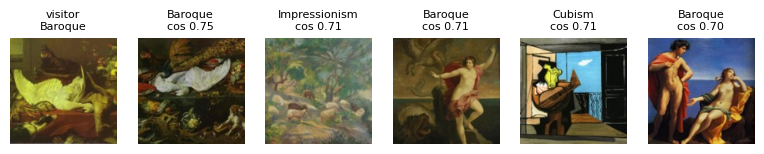

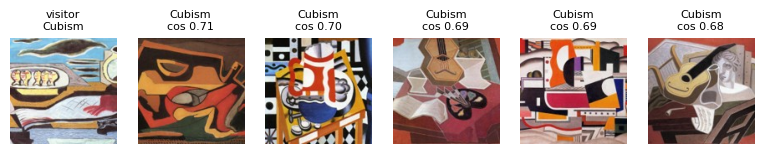

top-5 similar paintings with the same style: 71% (chance: 20%)


In [22]:
backbone = copy.deepcopy(model_tl)
backbone.fc = nn.Identity()                    # 512-d feature instead of 5 scores


def features(loader):
    backbone.eval()
    out = []
    with torch.no_grad():
        for xb, _ in loader:
            out.append(backbone(xb.to(device)).cpu())
    return F.normalize(torch.cat(out), dim=1)  # unit length: cosine = dot product


index = features(train_eval_loader)            # OFFLINE: the collection, (1000, 512)
queries = features(test_loader)                # ONLINE: the visitors' photos
print("index:", tuple(index.shape))

train_labels = train_loader.dataset.tensors[1]
for q in [0, 60]:                              # two test paintings
    scores = index @ queries[q]                # cosine similarity with all 1 000 paintings
    top = scores.topk(5).indices
    show_images(torch.cat([X_test_raw[q:q + 1], X_train_raw[top]]),
                [f"visitor\n{CLASSES[test_labels[q]]}"] + [f"{CLASSES[train_labels[i]]}\ncos {scores[i]:.2f}" for i in top],
                n=6)

# One number for the slides: how often the 5 nearest paintings have the same style as the visitor's photo
top5 = (queries @ index.T).topk(5, dim=1).indices          # (250, 5): the 5 most similar paintings of each test photo
same_style = (train_labels[top5] == test_labels.view(-1, 1)).float().mean().item()
print(f"top-5 similar paintings with the same style: {same_style:.0%} (chance: 20%)")

## Conclusion
The cell below prints the conclusion with the measured numbers (copy it to the slides).

In [23]:
best_mlp = MLP_ACC
print(f"""- Step A (head only, {n_trainable:,} trained parameters): test accuracy {acc_head:.3f}, macro-F1 {f1_head:.3f}.
  ImageNet features already separate the styles: {(acc_head - best_mlp) * 100:+.0f} points over the best MLP ({best_mlp}).
- Step B (layer4 + head, {count_parameters(model_tl, trainable_only=True):,} trained parameters): test accuracy {acc_ft:.3f}, macro-F1 {f1_ft:.3f}
  ({(acc_ft - acc_head) * 100:+.0f} points vs step A; about ±3 points is noise with 250 test images).
- Overfitting in step B: train loss {min(history_ft['train_loss']):.3f} vs val loss {history_ft['val_loss'][-1]:.3f} at the end -> early stopping keeps the best epoch.
- Most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times). MLP: Cubism -> Impressionism (30 times).
- Cost on a kiosk CPU (1 core): ResNet {lat_resnet:.1f} ms per image and {size_mb:.0f} MB; MLP {lat_mlp:.2f} ms and {size_mlp:.1f} MB.
- VSS idea: with τ = {TAU}, the guide answers {(test_probs.max(dim=1).values >= TAU).float().mean():.0%} of the test paintings;
  the 512-d features also give "similar artworks" with one matrix product: {same_style:.0%} of the top-5 have the same style.""")

- Step A (head only, 2,565 trained parameters): test accuracy 0.732, macro-F1 0.734.
  ImageNet features already separate the styles: +38 points over the best MLP (0.356).
- Step B (layer4 + head, 8,396,293 trained parameters): test accuracy 0.776, macro-F1 0.776
  (+4 points vs step A; about ±3 points is noise with 250 test images).
- Overfitting in step B: train loss 0.012 vs val loss 0.867 at the end -> early stopping keeps the best epoch.
- Most frequent mistake: Cubism predicted as Pop_Art (13 times). MLP: Cubism -> Impressionism (30 times).
- Cost on a kiosk CPU (1 core): ResNet 25.4 ms per image and 45 MB; MLP 0.57 ms and 12.8 MB.
- VSS idea: with τ = 0.7, the guide answers 83% of the test paintings;
  the 512-d features also give "similar artworks" with one matrix product: 71% of the top-5 have the same style.
